# HEART / Ugi-4CR × LNPDB | One-Notebook Pre-Continual Audit

**目的：一次性完成正式 continual pretraining 之前的資料審查、Ugi Step-0 baseline（選用 GPU）與 LNPDB ingestion 策略。**

- **Source of truth**：HPC Project 的 Ugi Stage-04 LMDB + `splits.json` + 已驗證的 3D slot sidecar；不更改既有資料、分割與 checkpoint。
- **資料量**：Ugi 15,182,715 records（3,049 shards）；General 18,837,320 train / 98,844 valid；LNPDB CSV 19,797 rows。
- **不增加任何 sbatch 或正式 Python 模組。** 只在 `audits/` 寫一次性報告、索引 SQLite 與固定評估 subset。
- **要謹慎**：Stage-05 原始 QC FAIL 仍保持原樣；獨立 3D-aware readiness 由 Stage-06 receipt 表示。既有 train/valid 是 **whole-shard split，不是 reagent-holdout**。
- **重點**：不要把 19,797 個 formulation rows 當作 19,797 個獨立 molecular pretraining examples；要以 canonical `IL_SMILES` 的唯一分子為單位。

**檔案位置**：保留原始 `LNPDB.csv`（不修改）於 `/project/yli4/ypan/lipid_library/input/LNPDB.csv`；Notebook 可置於 `/home/ypan/` 或專案其他位置。所有產生的候選結構與 audit 結果寫入 `audits/pre_continual_ugi_lnpdb/`，**不會寫回 `input/`**。

**執行方式**：在包含 RDKit 的 Jupyter kernel 先執行輕量 Section 0–2。15M+ 的完整 canonical audit 要使用足夠的 CPU／儲存資源，手動開啟 `RUN_FULL_UGI_CANONICAL`；GPU baseline 只有在 H200 allocation 時才啟用，不能直接使用 T4 的 Jupyter kernel。

## 0 | Configuration & operational switches

**預設只跑輕量分析，不會自動開始 15M / 18M 掃描或 CUDA evaluation。**

正式訓練前若要得到完整 Ugi canonical duplicate/跨 split 數據，請先設 `RUN_FULL_UGI_CANONICAL=True` 完成一次；結果可快取重用。General–Ugi canonical overlap 是獨立且更慢的工作。Step-0 GPU 評估只在 H200 環境啟用。

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import os, sys, json, csv, gzip, pickle, sqlite3, hashlib, time, bisect, random, shutil, math
from datetime import datetime, timezone
from IPython.display import display, Markdown

REPO = Path('/home/ypan/heart_liver/model_train/heart-molecular-pretraining')
INPUT = Path('/project/yli4/ypan/lipid_library/input')
UGI = Path('/project/yli4/ypan/lipid_library/lmdb')
VIEW = Path('/project/yli4/ypan/audits/ugi_3d_final_view')
GENERAL = Path('/project/yli4/ypan/UniMolReference/ligand_data/ligands')
GENERAL_CKPT = Path('/project/yli4/ypan/runs/h200/full/heart-h200-b448-v1/checkpoint_best.pt')
SMOKE_CKPT = Path('/project/yli4/ypan/runs/h200/continual/heart-lipid-continual-smoke/checkpoint_last.pt')  # 只比較時使用，不代表正式訓練結果
AUDIT = Path('/project/yli4/ypan/audits/pre_continual_ugi_lnpdb') if UGI.exists() else Path.cwd()/'HEART_Ugi_LNPDB_Audit_Outputs'

RUN_FULL_UGI_CANONICAL = False      # 很慢；對全部 3049 個 metadata CSV 的 canonical identity 做 full audit
RUN_FULL_GENERAL_CROSS = False     # 更慢；遍歷 General train/valid numeric-keyed LMDB 與 Ugi canonical DB 比較
RUN_STEP0_EVAL = False             # 需要能執行 CUDA 模型的 kernel；只讀取 checkpoint
RUN_COMPARE_SMOKE = False         # 可選：同一 Ugi subset 上比較 200-step smoke；非正式學習結論
N_STEP0_VALID = 512                # 固定 evaluation-only Ugi valid subset；可調，清單有快取
EVAL_BATCH_SIZE = 8               # 用較小 batch 避免過度消耗 GPU
SEED = 20261117

CSV_OPTIONS = [INPUT/'LNPDB.csv', INPUT/'LNPDB(3).csv', Path.cwd()/'LNPDB.csv', Path.cwd()/'LNPDB(3).csv', Path('/home/ypan/LNPDB.csv'), Path('/mnt/data/LNPDB(3).csv')]
LNPDB_CSV = next((p for p in CSV_OPTIONS if p.is_file()), None)
AUDIT.mkdir(parents=True,exist_ok=True)
print('Repository:', REPO, '[exists]', REPO.is_dir())
print('Ugi LMDB:', UGI, '[exists]', UGI.is_dir())
print('3D-view:', VIEW, '[exists]', (VIEW/'final_dataset_view.json').is_file())
print('General:', GENERAL, '[exists]', (GENERAL/'train.lmdb').is_file())
print('LNPDB CSV:', LNPDB_CSV or 'NOT FOUND (upload alongside notebook)')
print('Report dir:', AUDIT)
assert LNPDB_CSV is not None, '找不到 LNPDB.csv；請把原始 CSV 上傳至 /project/yli4/ypan/lipid_library/input/LNPDB.csv。'

Repository: /home/ypan/heart_liver/model_train/heart-molecular-pretraining [exists] False
Ugi LMDB: /project/yli4/ypan/lipid_library/lmdb [exists] False
3D-view: /project/yli4/ypan/audits/ugi_3d_final_view [exists] False
General: /project/yli4/ypan/UniMolReference/ligand_data/ligands [exists] False
LNPDB CSV: /mnt/data/LNPDB(3).csv
Report dir: /mnt/data/HEART_Ugi_LNPDB_Audit_Outputs


## 1 | Existing data integrity: inventory only（快速）

目的：讀既有 report / manifest / 3D-view / split；**不重新掃描 shards 或 SHA-256**。將 `READY` 和 `original Stage-05 QC` 分開呈現。這一節只是資料身份檢查，不取代已完成的 Stage 06 full verification。

In [2]:
def read_json_optional(path):
    try:
        return json.loads(Path(path).read_text())
    except (OSError, json.JSONDecodeError):
        return None

manifest = read_json_optional(UGI/'manifest.json')
splits = read_json_optional(UGI/'splits.json')
qc = read_json_optional(UGI/'quality_report.json')
view = read_json_optional(VIEW/'final_dataset_view.json')
ready = read_json_optional(UGI/'library_3d_ready.json')

for name, report in [('manifest',manifest),('splits',splits),('original Stage05 QC',qc),('3D view',view),('3D readiness',ready)]:
    print(f'{name:22}: {"present" if report else "NOT AVAILABLE"}')
if manifest and splits:
    ms = set(str(s['lmdb']) for s in manifest.get('shards', []))
    tr, va = (set(map(str, splits.get(k, []))) for k in ('train','valid'))
    print('Ugi manifest records:',manifest.get('n_records'),'shards:',len(ms))
    print('Split:',{k:len(splits.get(k,[])) for k in ('train','valid')},
          'record counts:',splits.get('n_records'))
    print('PASS disjoint shards:',not bool(tr & va), 'PASS full coverage:',tr | va == ms)
    assert not tr & va and tr | va == ms
if view:
    print('VIEW source:',view.get('source_lmdb_dir'))
    print('VIEW success counts:',view.get('stored_records'), 'fallback records:',view.get('fallback_containing_records_preserved'))
    print('VIEW flags:', 'index validated =',view.get('data_index_validated'),
          '; original QC passed =',view.get('source_original_quality_passed'))
if qc: print('Original stage05 QC passed (historical):',qc.get('passed'))
if ready: print('3D-ready receipt exists; full meaning is defined by the installed Stage06 code, not by this inventory.')

manifest              : NOT AVAILABLE
splits                : NOT AVAILABLE
original Stage05 QC   : NOT AVAILABLE
3D view               : NOT AVAILABLE
3D readiness          : NOT AVAILABLE


## 2 | LNPDB CSV schema / experiment heterogeneity / RDKit chemical audit

這節直接使用提供的 **66-column** LNPDB CSV。統計單位分三類：

1. `LNP_ID`（表格 row；可能是 formulation/assay entry）
2. unique **neutral `IL_SMILES`**（candidate molecular pretraining units）
3. `Experiment_value` + `Experiment_method` + `Model_type` + `Cargo` + formulation ratios（supervised context；不可當作同一種無條件標籤）

`IL_protonated_SMILES` 是另外一個明示的質子化表示，**不應無條件與 neutral 當作兩個獨立分子**。注意 269 筆 row 缺少 `Formulation_ID` 等欄位，不能假定都是完整可監督訓練的 records。

**實際 CSV provenance**：19,528 rows 有 `Formulation_ID`；另外 269 rows 來源是 `BroadPharm_2024` 的 lipid catalog，沒有 `Experiment_value` 或 assay method，僅能用於 molecular structure 的候選資料。與 2026 LNPDB 論文描述的 42 studies + commercial supplier 一致，但本次 canonical counts 依照 CSV 自行重新計算。

In [3]:
from rdkit import Chem, RDLogger
RDLogger.DisableLog('rdApp.*')
from rdkit.Chem import Descriptors

MISSING={'','na','none','null','nan','n/a','-'}
def present(x): return str(x or '').strip().lower() not in MISSING
def canonical(s):
    if not present(s): return None
    mol = Chem.MolFromSmiles(str(s).strip())
    return Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True) if mol is not None else None

def fingerprint(s):
    return hashlib.blake2b(s.encode('utf8'), digest_size=16).digest()

with open(LNPDB_CSV, encoding='utf-8-sig', newline='') as f:
    dr = csv.DictReader(f)
    columns = dr.fieldnames
    assert 'IL_SMILES' in columns and 'Experiment_value' in columns and 'LNP_ID' in columns
    lnp_rows = list(dr)

canon_cache={}; molfacts={}; invalid=[]; il_occ=Counter()
for r in lnp_rows: il_occ[r['IL_SMILES']]+=1
for smi in il_occ:
    m=Chem.MolFromSmiles(smi) if present(smi) else None
    if m is None:
        invalid.append(smi[:150]); continue
    can=Chem.MolToSmiles(m, canonical=True, isomericSmiles=True)
    canon_cache[smi]=can
    molfacts[can]={'heavy_atoms':m.GetNumHeavyAtoms(), 'formal_charge':Chem.GetFormalCharge(m),
                   'n_fragments':len(Chem.GetMolFrags(m)), 'molecular_weight':round(Descriptors.MolWt(m),2)}

unique_can=set(canon_cache.values())
num_missing_value=sum(not present(r['Experiment_value']) for r in lnp_rows)
num_missing_formulation=sum(not present(r['Formulation_ID']) for r in lnp_rows)
num_oversize=sum(a['heavy_atoms']>256 for a in molfacts.values())
experiment_methods=Counter((r['Experiment_method'] or '<missing>') for r in lnp_rows)
model_types=Counter((r['Model_type'] or '<missing>') for r in lnp_rows)
cargo_types=Counter((r['Cargo'] or '<missing>') for r in lnp_rows)
print(f'Rows: {len(lnp_rows):,}; columns: {len(columns)}; publications: {len(set(r["Publication_link"] for r in lnp_rows))}')
print(f'Raw IL SMILES: {len(il_occ):,}; canonical distinct IL: {len(unique_can):,}; invalid distinct IL: {len(invalid):,}')
print('Unique IL >256 heavy atoms:',num_oversize,'(assess against current HEART max_atoms policy)')
print('Missing Formulation_ID:',num_missing_formulation, '; missing Experiment_value:',num_missing_value)
print('Methods:',experiment_methods.most_common(12))
print('Cargo:',cargo_types)
print('Model types:',model_types.most_common(12))
assert not invalid, '有無法 parse 的 IL_SMILES；必須先分析 invalid list，不能直接轉 training input。'

LNP_SUMMARY={'rows':len(lnp_rows),'columns':len(columns),'raw_unique_IL_SMILES':len(il_occ),
             'canonical_unique_IL':len(unique_can),'invalid_unique_IL':len(invalid),
             'IL_canonical_over_256_heavy_atoms':num_oversize,
             'missing_formulation_ID_rows':num_missing_formulation,
             'missing_experiment_value_rows':num_missing_value,
             'experiment_methods':dict(experiment_methods), 'cargo':dict(cargo_types)}
(AUDIT/'lnpdb_csv_audit.json').write_text(json.dumps(LNP_SUMMARY,indent=2,ensure_ascii=False)+'\n')

Rows: 19,797; columns: 66; publications: 43
Raw IL SMILES: 12,844; canonical distinct IL: 12,835; invalid distinct IL: 0
Unique IL >256 heavy atoms: 5 (assess against current HEART max_atoms policy)
Missing Formulation_ID: 269 ; missing Experiment_value: 597
Methods: [('luminescence_normalized', 14630), ('luminescence_discretized_normalized', 3058), ('protein_adundance_normalized', 766), ('uptake', 479), ('<missing>', 269), ('editing_efficiency_normalized', 141), ('LRP6_knockdown_normalized', 112), ('diameter', 96), ('zeta_potential', 96), ('hemolysis_percent', 90), ('luminescence_relative_to_Spikevax', 60)]
Cargo: Counter({'mRNA': 14578, 'siRNA': 3758, 'pDNA': 1192, '<missing>': 269})
Model types: [('HeLa', 7783), ('A549', 2569), ('HepG2', 2000), ('Mouse_B6', 1818), ('DC2.4', 1703), ('IGROV1', 1202), ('RAW264.7', 1200), ('Mouse_BALBc', 359), ('<missing>', 269), ('BeWo_b30', 260), ('HEK293T', 256), ('Mouse_Ai14', 141)]


742

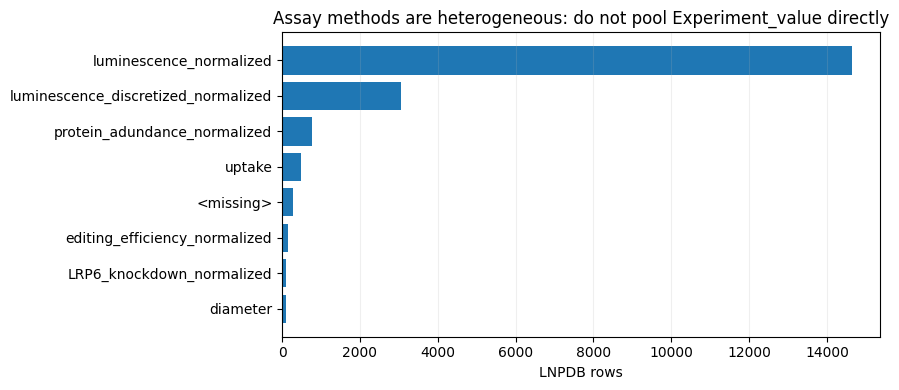

In [4]:
# Visual data audit from the actual LNPDB file (not estimates)
import matplotlib.pyplot as plt
m=experiment_methods.most_common(8)
fig,ax=plt.subplots(figsize=(9,4))
ax.barh([x[0] for x in m][::-1],[x[1] for x in m][::-1])
ax.set_xlabel('LNPDB rows')
ax.set_title('Assay methods are heterogeneous: do not pool Experiment_value directly')
ax.grid(axis='x',alpha=0.2)
plt.tight_layout()
plt.show()


In [5]:
# 只輸出候選 unique IL molecule table，不將重複測試列變成重複訓練分子。
by_can={}
for r in lnp_rows:
    can=canon_cache.get(r['IL_SMILES'])
    if not can: continue
    v=by_can.setdefault(can,{'count':0,'name':r['IL_name'], 'neutral_smiles':r['IL_SMILES'],
                              'protonated_smiles':r.get('IL_protonated_SMILES',''),
                              'sources':set(),'methods':set()})
    v['count']+=1
    if present(r['Publication_link']): v['sources'].add(r['Publication_link'])
    if present(r['Experiment_method']): v['methods'].add(r['Experiment_method'])

candidate_path=AUDIT/'lnpdb_unique_il_candidates.csv'
with open(candidate_path,'w',encoding='utf-8',newline='') as f:
    fields=['IL_canonical_SMILES','IL_original_SMILES','IL_protonated_SMILES','IL_name_example',
            'n_LNPDB_rows','heavy_atoms','formal_charge','n_sources','n_experiment_methods','passes_max_atoms_256']
    w=csv.DictWriter(f,fieldnames=fields);w.writeheader()
    for can,v in sorted(by_can.items()):
        facts=molfacts[can]
        w.writerow({'IL_canonical_SMILES':can,'IL_original_SMILES':v['neutral_smiles'],
                    'IL_protonated_SMILES':v['protonated_smiles'], 'IL_name_example':v['name'],
                    'n_LNPDB_rows':v['count'], 'heavy_atoms':facts['heavy_atoms'],
                    'formal_charge':facts['formal_charge'], 'n_sources':len(v['sources']),
                    'n_experiment_methods':len(v['methods']),
                    'passes_max_atoms_256':int(facts['heavy_atoms']<=256)})
print('Saved unique IL candidate table:',candidate_path)
print('Note: candidate table is NOT a ready-to-train LMDB. Protonated states and 3D policy need explicit design.')

Saved unique IL candidate table: /mnt/data/HEART_Ugi_LNPDB_Audit_Outputs/lnpdb_unique_il_candidates.csv
Note: candidate table is NOT a ready-to-train LMDB. Protonated states and 3D policy need explicit design.


### What LNPDB can and cannot do for HEART

| LNPDB column groups | Recommended representation | Use |
|---|---|---|
| `IL_SMILES`, `IL_protonated_SMILES` | canonical unique IL molecular graph; neutral/protonation paired metadata | **Molecular pretraining candidates**, after source overlap, max-atoms and 3D policy review |
| `IL_head_SMILES`, `IL_linker_SMILES`, `IL_tail*_SMILES` | explicit fragment annotations where available | Structure-aware probing/auxiliary evaluation; many missing, not required for initial pretraining |
| `IL_molratio`, `HL/CHL/PEG_*`, `Aqueous_buffer`, `Mixing_method` | formulation + process context | **Future supervised formulation model**, not a field of a single-molecule LMDB |
| `Model_type`, `Model_target`, `Cargo`, `Cargo_type`, `Route_of_administration`, `Dose_ug_nucleicacid` | assay context | Condition-specific delivery prediction only |
| `Experiment_method`, `Experiment_value`, `Publication_link` | provenance and target with assay-specific standardization | **Never blindly pool into one regression target** |

**Recommended order**: (A) 原始 LNPDB CSV 留在 `lipid_library/input/` 不動；先做 Ugi Step-0 baseline，再開始既定的 Ugi continual run, (B) check canonical LNPDB–Ugi/General overlap, (C) optionally add **unique IL molecular subset** as a separately weighted training source with existing molecular objectives and compatible 3D slots, (D) only later train a *separate supervised* formulation/delivery head using per-assay grouped splits. LNPDB labels must not be used to tune the self-supervised validation benchmark inadvertently.

## 3 | Ugi canonical duplicate & train/validation molecular leakage audit

用 `shard-xxxxx/records.csv.gz` 內的 `smi` / `key`；**不須重讀 3,049 個 LMDB**。以 RDKit **isomeric canonical SMILES** 去重，SQLite BLAKE2b-128 canonical hashes 磁碟索引，從而避免把 15M entries 全放進 Jupyter 記憶體。

- SQLite 是**一次性 audit cache**，不會動現有 LMDB 或 `splits.json`。每個 shard 處理完才 commit，可中斷續跑。
- Exact identity 是 canonical（保留 stereochemistry / charge）；較寬鬆 neutralization / tautomer mapping 是另一個科學決策，不能自動合併。
- **FULL** 只有在全部 manifest shards、record counts 與 split 都檢查完成時才能宣稱；default 是 OFF。

In [6]:
UGI_DB=AUDIT/'ugi_canonical_audit.sqlite3'

def open_ugi_db():
    c=sqlite3.connect(str(UGI_DB), timeout=120)
    c.execute('PRAGMA journal_mode=DELETE')
    c.execute('PRAGMA synchronous=NORMAL')
    c.execute('PRAGMA cache_size=-131072')  # ~128MB per connection
    c.execute('CREATE TABLE IF NOT EXISTS meta (k TEXT PRIMARY KEY, v TEXT NOT NULL)')
    c.execute('''CREATE TABLE IF NOT EXISTS ugi (
        key BLOB PRIMARY KEY, split_mask INTEGER NOT NULL, n_records INTEGER NOT NULL,
        seen_general INTEGER NOT NULL DEFAULT 0)''')
    c.execute('CREATE TABLE IF NOT EXISTS done (shard TEXT PRIMARY KEY, n_records INTEGER NOT NULL)')
    return c

def project_shard_inputs():
    if not (manifest and splits):
        raise FileNotFoundError('Project UGI manifest/splits missing; move notebook to HPC for full Ugi audit')
    splitmap={str(rel):bit for role,bit in [('train',1),('valid',2)] for rel in splits[role]}
    infos=[]
    for s in manifest['shards']:
        rel=str(s['lmdb'])
        if rel not in splitmap:raise ValueError(f'Shard not in splits: {rel}')
        p=UGI/Path(rel).parent/'records.csv.gz'
        infos.append((rel,p,splitmap[rel],int(s['n_records'])))
    return infos

if manifest and splits:
    print('Expected full canonical audit:',len(manifest['shards']),'shards,',manifest['n_records'],'records')
else: print('HPC not mounted: full Ugi audit not possible here (LNPDB section still works)')

HPC not mounted: full Ugi audit not possible here (LNPDB section still works)


In [7]:
def full_ugi_canonical_audit():
    inputs=project_shard_inputs()
    con=open_ugi_db()
    source_sha=hashlib.sha256((UGI/'manifest.json').read_bytes()).hexdigest()
    got=con.execute("SELECT v FROM meta WHERE k='manifest_sha256'").fetchone()
    if got and got[0]!=source_sha:
        con.close()
        raise RuntimeError('Audit DB is for a DIFFERENT manifest. Do not reuse; move/rename audit DB explicitly.')
    con.execute("INSERT OR IGNORE INTO meta(k,v) VALUES ('manifest_sha256',?)",(source_sha,))
    con.commit()
    done={p:n for p,n in con.execute('SELECT shard,n_records FROM done')}
    stamp=time.monotonic()
    for ix,(rel,meta_path,split_bit,n_expected) in enumerate(inputs,1):
        if rel in done:
            if done[rel]!=n_expected:raise ValueError('cached shard n_records mismatch: '+rel)
            continue
        if not meta_path.is_file():raise FileNotFoundError(meta_path)
        seen=0
        with con:  # one atomic transaction per shard
            with gzip.open(meta_path,'rt',encoding='utf-8',newline='') as f:
                reader=csv.DictReader(f)
                if not {'key','smi','n_3d_success'}.issubset(set(reader.fieldnames or [])):
                    raise ValueError('Unexpected records.csv.gz fields in '+str(meta_path))
                for row in reader:
                    if int(row['key']) != seen:raise ValueError('Noncontiguous record key in '+rel)
                    if int(row['n_3d_success'])<1:raise ValueError('Unexpected 0-good-3D record '+rel)
                    can=canonical(row['smi'])
                    if can is None:raise ValueError('Unparseable Ugi SMILES '+rel+' @ key='+row['key'])
                    con.execute('''INSERT INTO ugi(key,split_mask,n_records) VALUES (?,?,1)
                        ON CONFLICT(key) DO UPDATE SET
                        split_mask=(ugi.split_mask | excluded.split_mask), n_records=ugi.n_records+1''',
                        (fingerprint(can),split_bit))
                    seen+=1
            if seen!=n_expected:raise ValueError(f'{rel}: expected {n_expected}, found {seen}')
            con.execute('INSERT INTO done(shard,n_records) VALUES(?,?)',(rel,seen))
        if ix%50==0 or ix==len(inputs):
            print(f'processed {ix}/{len(inputs)} manifests, {time.monotonic()-stamp:.0f}s elapsed', flush=True)
    n_shards, n_rows=con.execute('SELECT COUNT(*),COALESCE(SUM(n_records),0) FROM done').fetchone()
    u, extra, crossing=con.execute('''SELECT COUNT(*), COALESCE(SUM(n_records-1),0),
        COALESCE(SUM(CASE WHEN split_mask=3 THEN 1 ELSE 0 END),0) FROM ugi''').fetchone()
    full=(n_shards==len(inputs) and n_rows==manifest['n_records'])
    report={'scope':'FULL' if full else 'PARTIAL', 'manifest_sha256':source_sha,
            'done_shards':n_shards,'expected_shards':len(inputs),'audited_records':n_rows,
            'unique_canonical_ugi':u,'duplicate_excess':extra,
            'canonical_train_valid_intersection':crossing,
            'method':'RDKit canonical isomeric SMILES hashed BLAKE2b-128'}
    (AUDIT/'ugi_canonical_audit_summary.json').write_text(json.dumps(report,indent=2)+'\n')
    con.close();return report

if RUN_FULL_UGI_CANONICAL:
    report=full_ugi_canonical_audit()
    print(json.dumps(report,indent=2))
    assert report['scope']=='FULL', '只有 FULL 可作為完整 train/valid leak 結論'
else:
    prev=read_json_optional(AUDIT/'ugi_canonical_audit_summary.json')
    print('Full Ugi canonical audit OFF. Existing report:',prev or 'NONE')

Full Ugi canonical audit OFF. Existing report: NONE


## 4 | LNPDB ↔ Ugi molecular overlap（完成上一節後可立即做）

使用相同 canonicalization policy；這回答 *LNPDB 到底有多少 molecular novelty*，避免把 LNPDB 的重複 formulation 列誤認成獨立的 chemical space。只有在上一節顯示 `scope=FULL` 後，才能宣稱完整 overlap；否則本節 **SKIP**，不是 `0 overlap`。

In [8]:
prev_ugi=read_json_optional(AUDIT/'ugi_canonical_audit_summary.json')
if prev_ugi and prev_ugi.get('scope')=='FULL' and UGI_DB.exists():
    con=open_ugi_db()
    matched=[]
    for can in unique_can:
        if con.execute('SELECT 1 FROM ugi WHERE key=?',(fingerprint(can),)).fetchone():
            matched.append(can)
    con.close()
    novel=unique_can.difference(matched)
    answer={'lnpdb_unique_canonical':len(unique_can),'matched_ugi':len(matched),'not_matched_ugi':len(novel),
            'ugi_audit_manifest_sha256':prev_ugi['manifest_sha256']}
    (AUDIT/'lnpdb_ugi_overlap.json').write_text(json.dumps(answer,indent=2)+'\n')
    print(answer)
else:
    print('SKIP: a completed full Ugi canonical audit is required; current overlap is UNKNOWN, not zero.')

SKIP: a completed full Ugi canonical audit is required; current overlap is UNKNOWN, not zero.


## 5 | General ↔ Ugi molecular overlap（只做一次，按需啟用）

已有 General historical audit 顯示 train **18,837,320** LMDB records、**13,270,476** unique raw SMILES（不是 canonical；此前已有驗證）。如果要精確知道 General 與 Ugi 有多少 canonical structure 相同，必須對 **General numeric LMDB keys** 逐筆掃描並使用同一 canonical policy。

本節可在上一步完成 FULL Ugi database 後執行；**一批 batch commit、可續跑**。進度存儲在 SQLite `general_done`。這是耗時的 CPU + I/O 工作，請在合適的 HPC CPU allocation 執行。不要將未掃描/部分掃描結果當作全量結論。

In [9]:
def scan_general_overlap(batch_size=10000):
    if not prev_ugi or prev_ugi.get('scope')!='FULL':
        raise RuntimeError('First complete full Ugi canonical audit')
    import lmdb
    con=open_ugi_db()
    con.execute('''CREATE TABLE IF NOT EXISTS general_done (
        split TEXT NOT NULL, start_key INTEGER NOT NULL, stop_key INTEGER NOT NULL,
        n_matched_rows INTEGER NOT NULL, PRIMARY KEY(split,start_key))''')
    con.commit()
    totals={}
    for split in ['train','valid']:
        src=GENERAL/(split+'.lmdb')
        if not src.is_file():raise FileNotFoundError(src)
        env=lmdb.open(str(src),subdir=False,readonly=True,lock=False,readahead=False,max_readers=32)
        try:
            with env.begin(write=False) as txn:
                size=txn.stat()['entries']
                previous={st:(en,n) for st,en,n in con.execute(
                    'SELECT start_key,stop_key,n_matched_rows FROM general_done WHERE split=?',(split,))}
                for start in range(0,size,batch_size):
                    stop=min(start+batch_size,size)
                    if start in previous:
                        if previous[start][0]!=stop:raise RuntimeError('Changed batch length/LMDB size: '+split)
                        continue
                    matched=0
                    keys=set()
                    for idx in range(start,stop):
                        raw=txn.get(str(idx).encode('ascii'))
                        if raw is None:raise KeyError(f'{split} LMDB missing numeric key {idx}')
                        record=pickle.loads(raw)
                        smi=record.get('smi') or record.get('smiles')
                        can=canonical(smi)
                        if can is None:raise ValueError(f'General invalid SMILES: {split} / {idx}')
                        key=fingerprint(can)
                        if con.execute('SELECT 1 FROM ugi WHERE key=?',(key,)).fetchone():
                            matched+=1;keys.add(key)
                    with con:
                        for key in keys:con.execute('UPDATE ugi SET seen_general=1 WHERE key=?',(key,))
                        con.execute('INSERT INTO general_done VALUES(?,?,?,?)',(split,start,stop,matched))
                    if start%(batch_size*100)==0:
                        print(f'General {split}: {stop:,}/{size:,} numeric records',flush=True)
                n_checked,n_matched=con.execute('SELECT SUM(stop_key-start_key),SUM(n_matched_rows) FROM general_done WHERE split=?',(split,)).fetchone()
                totals[split]={'checked':n_checked, 'n_records':size,'matched_record_occurrences':n_matched,
                               'scope':'FULL' if n_checked==size else 'PARTIAL'}
        finally:
            env.close()
    ugi_matched=con.execute('SELECT COUNT(*) FROM ugi WHERE seen_general=1').fetchone()[0]
    con.close()
    report={'general_overlap':totals,'ugi_canonical_structures_ever_seen_in_general':ugi_matched,
            'all_general_scanned':all(v['scope']=='FULL' for v in totals.values())}
    (AUDIT/'general_ugi_canonical_overlap.json').write_text(json.dumps(report,indent=2)+'\n')
    return report

if RUN_FULL_GENERAL_CROSS:
    print(json.dumps(scan_general_overlap(),indent=2))
else:
    print('General↔Ugi full comparison is OFF. This is NOT evidence of zero overlap.')

General↔Ugi full comparison is OFF. This is NOT evidence of zero overlap.


## 6 | Paired Ugi validation: Step-0 general checkpoint (optional H200 GPU)

**研究問題**：同一份 Ugi validation 上，General checkpoint（continual step 0）的 masked-atom hit/count、coordinate/distance losses 為何？

- Ugi validation subset 從既有 `splits.json` **deterministically** 採樣；使用 numeric LMDB key、3D-aware `n_3d_success`。只寫 evaluation-only 小型 LMDB 到 `audits/`，不更動正式 library。
- 為了使用 **原始 General checkpoint 的相同 objective/criterion**，evaluation-only 10 slots 由 verified 3D prefix 循環填充。這是 **matching protocol**（兩個 checkpoint 的同一測試輸入），不等同 production mixed-sampler 的精確實際曝露分布。
- 同批次、相同 random seed 與 mask/noise，才能直接比較。此 evaluation 使用 RDKit 不參與本身模型輸入。
- **正式報告應是 Step 0 vs sufficiently-trained checkpoint**；200-update smoke 可供技術對照，但不視為 learning conclusion。
- 在 T4 的 Jupyter terminal 預設 **不跑 GPU evaluation**；在 H200 GPU kernel 裡將 `RUN_STEP0_EVAL=True`。

In [10]:
def deterministic_ugi_valid_manifest(n=N_STEP0_VALID):
    if not (manifest and splits and view):
        raise RuntimeError('Need Project Ugi splits, manifest and index view')
    target=AUDIT/f'ugi_valid_{n}_seed{SEED}_manifest.json'
    if target.is_file():
        saved=read_json_optional(target)
        if saved and saved.get('n')==n and saved.get('seed')==SEED:
            return saved
    by_rel={str(s['lmdb']):s for s in manifest['shards']}
    pool=[(rel,int(by_rel[rel]['n_records'])) for rel in splits['valid']]
    size=sum(cnt for _,cnt in pool)
    if n>size:raise ValueError('n exceeds validation records')
    rng=random.Random(SEED)
    numeric=sorted(rng.sample(range(size), n))
    cums=[];total=0
    for rel,cnt in pool:
        total+=cnt;cums.append(total)
    chosen=[]
    for idx in numeric:
        j=bisect.bisect_right(cums,idx)
        first=0 if j==0 else cums[j-1]
        chosen.append({'lmdb':pool[j][0], 'key':idx-first})
    out={'n':n,'seed':SEED,'manifest_sha256':hashlib.sha256((UGI/'manifest.json').read_bytes()).hexdigest(),
         'samples':chosen,'evaluation_type':'evaluation-only Ugi valid, numeric LMDB keys'}
    target.write_text(json.dumps(out,indent=2)+'\n')
    return out

if manifest and splits and view:
    eval_manifest=deterministic_ugi_valid_manifest()
    print('Saved/reused fixed Ugi validation list with',len(eval_manifest['samples']),'molecules')
else:
    eval_manifest=None
    print('No mounted HPC Ugi data: fixed validation manifest creation deferred.')

No mounted HPC Ugi data: fixed validation manifest creation deferred.


In [11]:
def build_eval_only_lmdb(override=False):
    import lmdb
    import numpy as np
    if not eval_manifest:raise RuntimeError('Need fixed Ugi manifest')
    folder=AUDIT/f'ugi_eval_{N_STEP0_VALID}_seed{SEED}'
    folder.mkdir(parents=True,exist_ok=True)
    out=folder/'valid.lmdb'
    vocab=folder/'dict.txt'
    if not vocab.exists():shutil.copy2(GENERAL/'dict.txt',vocab)
    if out.exists() and not override:return folder
    if out.exists():raise RuntimeError('Refusing to overwrite existing eval LMDB. Use a NEW AUDIT folder.')
    index_by_rel={str(e['lmdb']):e for e in view['shards']}
    by_shard=defaultdict(list)
    for outid,spec in enumerate(eval_manifest['samples']):
        by_shard[spec['lmdb']].append((outid,spec['key']))
    env_out=lmdb.open(str(out),subdir=False,map_size=2*1024**3)
    written=0
    try:
        with env_out.begin(write=True) as outtxn:
            for rel,selected in by_shard.items():
                e=index_by_rel[rel]
                counts=(VIEW/e['index']).read_bytes()
                env=lmdb.open(str(UGI/rel),subdir=False,readonly=True,lock=False,readahead=False)
                try:
                    with env.begin(write=False) as txn:
                        for outid,key in selected:
                            raw=txn.get(str(key).encode('ascii'))
                            if raw is None:raise KeyError(f'{rel} key {key} missing')
                            obj=pickle.loads(raw)
                            count=counts[key]
                            coords=obj['coordinates']
                            if not 1<=count<=10 or len(coords)!=10:raise ValueError('Unexpected conformer metadata')
                            # Evaluated molecules use only actual writer-successful 3D prefix, not 2D fallback.
                            new=dict(obj)
                            new['coordinates']=[np.asarray(coords[i%count]).copy() for i in range(10)]
                            outtxn.put(str(outid).encode('ascii'),pickle.dumps(new,protocol=pickle.HIGHEST_PROTOCOL))
                            written+=1
                finally:env.close()
        env_out.sync()
    finally:env_out.close()
    if written!=N_STEP0_VALID:raise ValueError('Missing eval records')
    print('Evaluation-only valid LMDB prepared:',out,'records',written)
    return folder

if RUN_STEP0_EVAL:
    EVAL_FOLDER=build_eval_only_lmdb()
else:
    EVAL_FOLDER=None
    print('Evaluation LMDB build OFF (switch RUN_STEP0_EVAL=True only in an H200 kernel).')

Evaluation LMDB build OFF (switch RUN_STEP0_EVAL=True only in an H200 kernel).


In [12]:
# Optional same-protocol paired objective evaluation: uses original HEART/Uni-Core task and criterion.
def paired_ugi_checkpoint_eval():
    import torch, numpy as np
    from argparse import Namespace
    if not torch.cuda.is_available():raise RuntimeError('Need CUDA H200 for this check')
    vram=torch.cuda.get_device_properties(0).total_memory/1024**3
    if vram<80:raise RuntimeError(f'GPU has only {vram:.1f} GiB; use an H200 session, not the T4 login/kernel')
    if not GENERAL_CKPT.is_file():raise FileNotFoundError(GENERAL_CKPT)
    if not EVAL_FOLDER:raise RuntimeError('First build evaluation-only LMDB')
    sys.path.insert(0,str((REPO/'model').resolve()))
    sys.path.insert(0,str((REPO/'model/pretrain').resolve()))
    unicore_src=Path('/home/ypan/heart_liver/model_train/third_party/Uni-Core')
    sys.path.insert(0,str(unicore_src.resolve()))
    import unimol
    from unicore import tasks
    assert (REPO/'model/unimol').resolve() in Path(unimol.__file__).resolve().parents, 'Wrong unimol import path'

    def load_trusted(path):
        # torch.load may invoke pickle: load ONLY trusted lab-produced checkpoints.
        return torch.load(str(path),map_location='cpu',weights_only=False)
    general_cp=load_trusted(GENERAL_CKPT)
    args=general_cp['args']
    args=Namespace(**args) if isinstance(args,dict) else args
    args.data=str(EVAL_FOLDER)
    args.mode='train'  # criterion requires masked inputs and targets
    args.num_workers=0
    if hasattr(args,'user_dir'):args.user_dir=str((REPO/'model/unimol').resolve())
    task=tasks.setup_task(args)
    criterion=task.build_loss(args).to('cuda:0').eval()
    task.load_dataset('valid',epoch=1)
    ds=task.dataset('valid')
    checkpoints=[('general_step0',GENERAL_CKPT,general_cp)]
    if RUN_COMPARE_SMOKE:
        if not SMOKE_CKPT.is_file():raise FileNotFoundError(SMOKE_CKPT)
        checkpoints.append(('smoke_200',SMOKE_CKPT,load_trusted(SMOKE_CKPT)))

    def gpu(x):
        if isinstance(x,torch.Tensor):return x.to('cuda:0')
        if isinstance(x,dict):return {k:gpu(v) for k,v in x.items()}
        if isinstance(x,(list,tuple)):return type(x)(gpu(v) for v in x)
        return x
    results=[]
    for label,path,cp in checkpoints:
        model=task.build_model(args)
        model.load_state_dict(cp['model'],strict=True)
        model=model.to('cuda:0').eval()
        total=Counter()
        with torch.no_grad():
            for start in range(0,N_STEP0_VALID,EVAL_BATCH_SIZE):
                random.seed(SEED+start);np.random.seed(SEED+start);torch.manual_seed(SEED+start)
                batch=ds.collater([ds[i] for i in range(start,min(start+EVAL_BATCH_SIZE,N_STEP0_VALID))])
                loss,ss,logs=criterion(model,gpu(batch))
                if not torch.isfinite(loss).all():raise FloatingPointError(f'{label} invalid loss on batch starting {start}')
                for k,v in logs.items():
                    if isinstance(v,torch.Tensor) and v.numel()!=1:continue
                    try:total[k]+=float(v.detach().cpu()) if hasattr(v,'detach') else float(v)
                    except (TypeError,ValueError):continue
        cnt=total['masked_token_cnt']
        row={'model':label,'checkpoint':str(path), 'evaluated_molecules':N_STEP0_VALID,
             'masked_atom_accuracy':total['masked_token_hit']/cnt if cnt else None,
             'masked_token_count':cnt, 'masked_atom_hit':total['masked_token_hit'],
             'mean_total_loss_per_batch':total['loss']/total['sample_size'] if total['sample_size'] else None}
        for k in ['masked_token_loss','masked_coord_loss','masked_dist_loss','contrastive_loss']:
            row[k]=total[k]/total['sample_size'] if total['sample_size'] else None
        results.append(row)
        print(label,row)
        del model;torch.cuda.empty_cache()
    (AUDIT/'ugi_checkpoint_paired_eval.json').write_text(json.dumps(results,indent=2)+'\n')
    return results

if RUN_STEP0_EVAL:
    EVAL_RESULTS=paired_ugi_checkpoint_eval()
else:
    print('GPU Step0 evaluation disabled; do not infer Step0 accuracy from smoke training logs.')

GPU Step0 evaluation disabled; do not infer Step0 accuracy from smoke training logs.


## 7 | Before production: one-time decision table (no automatic start)

| Criterion | Gate | Interpretation |
|---|---|---|
| Original library/3D view/splits | Existing Stage06 `library_3d_ready.json` + valid split | Smoke already suggests usable pipeline; avoid repeating full Stage06 hash |
| Ugi canonical duplicates + chemical split overlap | **Full Ugi canonical audit** | If cross-split canonical duplicate > 0, correct sampling/validation **before** using validation loss to pick models |
| General↔Ugi canonical overlap | Optional full scan / explicitly mark unknown | Quantifies novel chemistry; not always a reason to remove shared records |
| Ugi Step0 baseline | Trusted General checkpoint evaluated on fixed Ugi validation | Enables an actual *before→after* comparison; masked atom accuracy alone does not prove Ugi scaffold recognition |
| Training weights & exposure | Inspect `mixture_report.json` (weights are per-dataset sampling fractions, not fixed batch ratio) | Log actual General vs Ugi exposure; be alert to repeated sampling |
| Checkpoint initialization | New production RUN_NAME / no accidental smoke resume | Production should initialize from General checkpoint, not a test run |
| Molecular identity policy | canonical isomeric SMILES; preserve validated conformers | Never count conformers or repeated formulation tests as unique molecules |
| LNPDB addition | **Defer until overlap, max-atoms and 3D policy** | Ionizable-lipid pretraining versus formulation-level supervised task must be separate |

**Evaluation caveat:** Current Ugi split is *in-distribution whole-shard holdout*. It does not establish generalization to completely new Ugi reagents. For structural recognition, consider a future evaluation-only reagent-holdout set and matched Ugi/non-Ugi molecular probes; do not train to these tests.

In [13]:
# Compact final report; existing on-disk results are reused and never falsely called complete.
ugi_report=read_json_optional(AUDIT/'ugi_canonical_audit_summary.json')
general_report=read_json_optional(AUDIT/'general_ugi_canonical_overlap.json')
pair_report=read_json_optional(AUDIT/'ugi_checkpoint_paired_eval.json')
summary={
  'generated_at_utc':datetime.now(timezone.utc).isoformat(),
  'lnpdb':LNP_SUMMARY,
  'ugi_source_manifest_present':bool(manifest),
  'ugi_3d_view_present':bool(view),
  'ugi_library_3d_ready_receipt_present':bool(ready),
  'ugi_full_canonical_report':ugi_report,
  'general_ugi_full_overlap_report':general_report,
  'ugi_checkpoint_paired_eval':pair_report,
  'caution':'Missing report is UNKNOWN, not PASS. No training job submitted.',
}
final=AUDIT/'pre_continual_one_notebook_summary.json'
final.write_text(json.dumps(summary,indent=2,ensure_ascii=False)+'\n')
print('Saved',final)
print('FULL Ugi canonical:',ugi_report.get('scope') if ugi_report else 'NOT RUN')
print('FULL General cross:',general_report.get('all_general_scanned') if general_report else 'NOT RUN')
print('Ugi checkpoint baseline:', 'RECORDED' if pair_report else 'NOT RUN')
print('LNPDB canonical unique:',LNP_SUMMARY['canonical_unique_IL'])

Saved /mnt/data/HEART_Ugi_LNPDB_Audit_Outputs/pre_continual_one_notebook_summary.json
FULL Ugi canonical: NOT RUN
FULL General cross: NOT RUN
Ugi checkpoint baseline: NOT RUN
LNPDB canonical unique: 12835
